# Laboratorio OpenDSS & py-dss-interface
## Módulo 4: Integración de Recursos Distribuidos (DER) - Sistemas Fotovoltaicos (PV) y Almacenamiento (BESS)

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Modelar física y matemáticamente el fenómeno de **elevación de tensión** (*Voltage Rise*) provocado por la inyección de potencia activa de generadores distribuidos en redes de BT.
2. Definir e integrar objetos `PVSystem` en OpenDSS parametrizando curvas de temperatura, irradiancia y sobredimensionamiento de inversor (*DC/AC ratio*).
3. Configurar sistemas de almacenamiento electroquímico (`Storage` - BESS), gestionando su **Estado de Carga** ($SoC$), potencias de carga/descarga y rendimientos de conversión de ida y vuelta (*Round-Trip Efficiency*).
4. Diseñar una estrategia coordinada de **Peak Shaving** (recorte de picos de demanda nocturna) y absorción de excedentes solares a mediodía.
5. Cuantificar el alivio en la cargabilidad del transformador de distribución y la mitigación de sobretensiones.

---
### 1. Fundamento Analítico: Elevación de Tensión por Generación Distribuida

En un alimentador de distribución radial pasivo con impedancia en serie $\mathbf{Z} = R + jX$, la corriente fluye desde la subestación hacia la carga. La caída de tensión aproximada es:

$$\Delta V pprox rac{P \cdot R + Q \cdot X}{V_{	ext{nom}}}$$

Donde $P > 0$ es la potencia activa consumida y $Q > 0$ es la potencia reactiva inductiva.

En redes de baja tensión (BT), los conductores presentan una relación $R/X$ muy elevada ($R/X pprox 2.5 \sim 4.5$). Si se conecta un sistema fotovoltaico con generación neta $P_{	ext{gen}} > P_{	ext{carga}}$, el flujo neto de potencia activa se invierte ($P_{	ext{neto}} < 0$), lo que produce una **elevación de tensión**:

$$V_{	ext{nodo}} pprox V_{	ext{sub}} - rac{-P_{	ext{iny}} \cdot R + Q \cdot X}{V_{	ext{nom}}} = V_{	ext{sub}} + rac{P_{	ext{iny}} \cdot R - Q \cdot X}{V_{	ext{nom}}}$$

Si la inyección $P_{	ext{iny}}$ es suficientemente grande, $V_{	ext{nodo}}$ superará el límite regulatorio superior ($1.05	ext{ pu}$ o $1.10	ext{ pu}$), obligando a disparar protecciones o degradar la calidad del suministro.


In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

sys.path.append(os.getcwd())
from utils.lab_dss_toolkit import get_network_snapshot, plot_voltage_profile

# Instanciar OpenDSS y cargar la Red Laboratorio BT
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False
circuit_path = os.path.join(base_dir, "data", "circuit_lab_bt", "Master_LabBT.dss")
dss.text(f"compile '{circuit_path}'")
dss.solution.solve()

print("[OK] Red de Laboratorio BT inicializada.")


[OK] Red de Laboratorio BT inicializada.


---
### 2. Integración de Generación Fotovoltaica (`PVSystem`)

Añadiremos dos sistemas fotovoltaicos residenciales en los puntos más sensibles de la red:
* `PV_3`: Ubicado en `LoadBus_3.1` (Fase A), con capacidad nominal de $8.0	ext{ kWp}$ ($kVA = 8.5$).
* `PV_8`: Ubicado en `LoadBus_8.1` (Fase B), con capacidad nominal de $12.0	ext{ kWp}$ ($kVA = 13.0$).

Definimos una curva de eficiencia inversora estándar y asignamos operación a factor de potencia unitario ($PF = 1.0$).


In [2]:
# Crear curva de eficiencia del inversor
dss.text("New XYCurve.EffCurve npts=4 xarray=[0.1 0.2 0.5 1.0] yarray=[0.92 0.95 0.98 0.985]")

# Crear curva P-T de derrateo por temperatura de celda
dss.text("New XYCurve.PTCurve npts=4 xarray=[0 25 50 75] yarray=[1.1 1.0 0.88 0.75]")

# Agregar PV_3 en LoadBus_3.1 (Fase A)
dss.text("New PVSystem.PV_3 phases=1 bus1=LoadBus_3.1 kV=0.230 kVA=8.5 pmpp=8.0 irradiance=1.0 "
         "pf=1.0 effcurve=EffCurve P-TCurve=PTCurve %cutin=0.1 %cutout=0.1")

# Agregar PV_8 en LoadBus_8.1 (Fase B)
dss.text("New PVSystem.PV_8 phases=1 bus1=LoadBus_8.1 kV=0.230 kVA=13.0 pmpp=12.0 irradiance=1.0 "
         "pf=1.0 effcurve=EffCurve P-TCurve=PTCurve %cutin=0.1 %cutout=0.1")

# Resolver flujo con inyección solar plena al mediodía (irradiance = 1.0 pu)
dss.solution.solve()

snap_pv = get_network_snapshot(dss)
df_buses_pv = snap_pv["buses"]

print("=== IMPACTO DE LA INYECCIÓN FOTOVOLTAICA A MEDIODÍA ===")
print(df_buses_pv[["Bus", "Va_pu", "Vb_pu", "Vc_pu", "V_max_pu"]].to_string(index=False))


=== IMPACTO DE LA INYECCIÓN FOTOVOLTAICA A MEDIODÍA ===
          Bus    Va_pu    Vb_pu    Vc_pu  V_max_pu
    sourcebus 0.999980 0.999984 0.999984  0.999984
substation_bt 0.991704 0.989556 0.992906  0.992906
       node_1 0.985961 0.981519 0.982078  0.985961
       node_2 0.985133 0.974408 0.972834  0.985133
       node_3 0.984111 0.975692 0.969097  0.984111
       node_4 0.980921 0.970971 0.963881  0.980921
       node_5 0.975397 0.974428 0.956630  0.975397
       node_6 0.988004 0.981821 0.979679  0.988004
    loadbus_1 0.983675      NaN      NaN  0.983675
    loadbus_2 0.970580      NaN      NaN  0.970580
    loadbus_3 0.983344      NaN      NaN  0.983344
    loadbus_4 0.964895      NaN      NaN  0.964895
    loadbus_5 0.968986      NaN      NaN  0.968986
    loadbus_6 0.952114      NaN      NaN  0.952114
    loadbus_7 0.973116      NaN      NaN  0.973116
    loadbus_8 0.982131      NaN      NaN  0.982131


---
### 3. Visualización de la Sobretensión por Flujo Inverso

Al inyectar $12	ext{ kW}$ en el extremo del ramal sur (`LoadBus_8`), la tensión pasa de estar en caída ($0.945	ext{ pu}$) a una fuerte elevación:


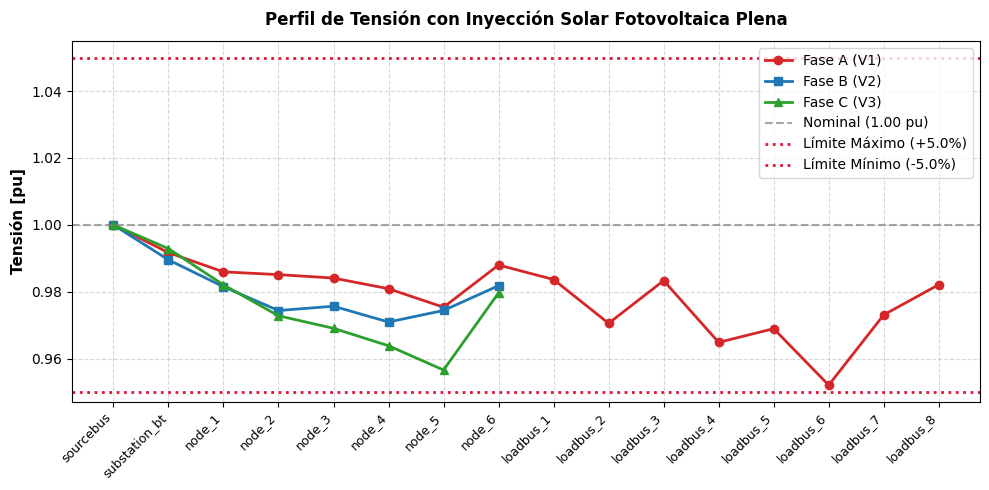

In [3]:
fig = plot_voltage_profile(df_buses_pv, v_min=0.95, v_max=1.05,
                           title="Perfil de Tensión con Inyección Solar Fotovoltaica Plena")
plt.show()


---
### 4. Integración y Modelado del Sistema de Almacenamiento (BESS)

Para mitigar la sobretensión a mediodía y aplanar la curva de carga durante el pico nocturno, instalamos un banco de baterías `BESS_8` en la barra `LoadBus_8.1`.

Parámetros técnicos de la batería:
* Capacidad de Potencia: $P_{	ext{rated}} = 8.0	ext{ kW}$
* Capacidad de Energía: $E_{	ext{rated}} = 25.0	ext{ kWh}$
* Rendimiento de Carga/Descarga: $\eta_{	ext{chg}} = 95\%$, $\eta_{	ext{dis}} = 95\%$ (Round-Trip $pprox 90\%$)
* Estado de Carga Inicial: $SoC_0 = 40\%$
* Reserva Mínima de Descarga: $20\%$


In [4]:
# Crear elemento de Almacenamiento BESS_8
dss.text("New Storage.BESS_8 phases=1 bus1=LoadBus_8.1 kV=0.230 "
         "kWrated=8.0 kWhrated=25.0 %stored=40.0 %reserve=20.0 "
         "%EffCharge=95.0 %EffDischarge=95.0 state=IDLE")

# Verificar creación del BESS
dss.storages.name = "bess_8"
print(f"BESS creado: {dss.storages.name.upper()}")
print(f"Potencia nominal: {dss.storages.kw_rated} kW | Capacidad energética: {dss.storages.kwh_rated} kWh")
print(f"Estado de Carga inicial (SoC): {dss.storages.pu_soc * 100:.1f}%")


BESS creado: BESS_8
Potencia nominal: 8.0 kW | Capacidad energética: 25.0 kWh
Estado de Carga inicial (SoC): 40.0%


---
### 5. Simulación de los Tres Modos de Operación del BESS

Evaluaremos la red en 3 estados operacionales clave:
1. **Modo Mediodía Solar con BESS en CARGA (`CHARGING`):** La batería absorbe el exceso de $6.0	ext{ kW}$ generado por `PV_8`, aliviando la sobretensión.
2. **Modo Pico Nocturno sin BESS (`IDLE`):** Cargas al máximo, sin sol, sobrecargando la red.
3. **Modo Pico Nocturno con BESS en DESCARGA (`DISCHARGING`):** La batería inyecta $7.0	ext{ kW}$ para abastecer localmente la demanda residencial.


In [5]:
# -------------------------------------------------------------
# Escenario 1: Mediodía Solar con BESS Absorbiendo Excedentes
# -------------------------------------------------------------
dss.text("Edit PVSystem.PV_8 irradiance=1.0")
dss.text("Edit Storage.BESS_8 state=CHARGING %Charge=75.0") # Carga a 6 kW
dss.solution.solve()

snap_mediodia = get_network_snapshot(dss)
dss.circuit.set_active_bus("loadbus_8")
v_mediodia_pu = np.sqrt(dss.bus.pu_voltages[0]**2 + dss.bus.pu_voltages[1]**2)

# -------------------------------------------------------------
# Escenario 2: Pico Nocturno SIN BESS (PV apagado, BESS IDLE)
# -------------------------------------------------------------
dss.text("Edit PVSystem.PV_3 irradiance=0.0")
dss.text("Edit PVSystem.PV_8 irradiance=0.0")
dss.text("Edit Storage.BESS_8 state=IDLE")
dss.solution.solve()

p_trafo_pico_sin_bess = abs(dss.circuit.total_power[0])
dss.circuit.set_active_bus("loadbus_8")
v_pico_sin_bess_pu = np.sqrt(dss.bus.pu_voltages[0]**2 + dss.bus.pu_voltages[1]**2)

# -------------------------------------------------------------
# Escenario 3: Pico Nocturno CON BESS Inyectando (DISCHARGING)
# -------------------------------------------------------------
dss.text("Edit Storage.BESS_8 state=DISCHARGING %Discharge=87.5") # Descarga a 7 kW
dss.solution.solve()

p_trafo_pico_con_bess = abs(dss.circuit.total_power[0])
dss.circuit.set_active_bus("loadbus_8")
v_pico_con_bess_pu = np.sqrt(dss.bus.pu_voltages[0]**2 + dss.bus.pu_voltages[1]**2)

print("=========================================================================")
print("            IMPACTO DE LA GESTIÓN DE BESS EN OPERACIÓN DIARIA")
print("=========================================================================")
print(f"Condición Operativa                 | Tensión LoadBus_8 | Potencia Subestación")
print(f"------------------------------------|-------------------|---------------------")
print(f"Mediodía Solar con BESS cargando    | {v_mediodia_pu:8.4f} pu       | {abs(dss.circuit.total_power[0]):8.2f} kW")
print(f"Pico Nocturno (BESS IDLE)           | {v_pico_sin_bess_pu:8.4f} pu       | {p_trafo_pico_sin_bess:8.2f} kW")
print(f"Pico Nocturno (BESS DESCARGANDO)    | {v_pico_con_bess_pu:8.4f} pu       | {p_trafo_pico_con_bess:8.2f} kW")
print("=========================================================================")
print(f"Alivio de demanda en el pico nocturno: {(p_trafo_pico_sin_bess - p_trafo_pico_con_bess):.2f} kW (Reducción del {((p_trafo_pico_sin_bess - p_trafo_pico_con_bess)/p_trafo_pico_sin_bess*100):.1f}%)")
print(f"Mejora de tensión nodal en pico: {(v_pico_con_bess_pu - v_pico_sin_bess_pu):+.4f} pu")


            IMPACTO DE LA GESTIÓN DE BESS EN OPERACIÓN DIARIA
Condición Operativa                 | Tensión LoadBus_8 | Potencia Subestación
------------------------------------|-------------------|---------------------
Mediodía Solar con BESS cargando    |   0.9631 pu       |    57.01 kW
Pico Nocturno (BESS IDLE)           |   0.9456 pu       |    64.58 kW
Pico Nocturno (BESS DESCARGANDO)    |   0.9688 pu       |    57.01 kW
Alivio de demanda en el pico nocturno: 7.57 kW (Reducción del 11.7%)
Mejora de tensión nodal en pico: +0.0233 pu


---
### 6. Ejercicio Guiado: Ciclo de Energía y Verificación de Estado de Carga ($SoC$)

**Consigna:**
Suponga que el BESS opera en descarga continua de $6.0	ext{ kW}$ durante $3	ext{ horas}$ de demanda pico (19:00 a 22:00):
1. Calcule la energía total extraída: $\Delta E = P_{	ext{dis}} \cdot \Delta t / \eta_{	ext{dis}}$.
2. Determine el nuevo $SoC$ final a partir de un $SoC_{	ext{inicial}} = 85\%$.
3. Verifique que el $SoC$ final no vulnere la reserva técnica del $20\%$.


In [6]:
soc_inicial = 85.0 # %
p_descarga_kw = 6.0
duracion_h = 3.0
eta_dis = 0.95
kwh_rated = 25.0
soc_reserva = 20.0

# Energía entregada a la red
energia_entregada_kwh = p_descarga_kw * duracion_h

# Energía drenada de las celdas químicas
energia_drenada_kwh = energia_entregada_kwh / eta_dis

# Variación del SoC
delta_soc_pct = (energia_drenada_kwh / kwh_rated) * 100.0
soc_final = soc_inicial - delta_soc_pct

print(f"=== BALANCE ENERGÉTICO DE LA BATERÍA ===")
print(f"Energía suministrada a la red: {energia_entregada_kwh:.2f} kWh")
print(f"Energía interna consumida:    {energia_drenada_kwh:.2f} kWh")
print(f"Variación del SoC:            -{delta_soc_pct:.1f}%")
print(f"SoC Final resultante:         {soc_final:.1f}%")

if soc_final >= soc_reserva:
    print(f"[OK] Criterio de reserva cumplido: SoC final ({soc_final:.1f}%) >= Reserva ({soc_reserva:.1f}%)")
else:
    print(f"[X] Alerta: Se vulnera la reserva mínima del {soc_reserva:.1f}%")


=== BALANCE ENERGÉTICO DE LA BATERÍA ===
Energía suministrada a la red: 18.00 kWh
Energía interna consumida:    18.95 kWh
Variación del SoC:            -75.8%
SoC Final resultante:         9.2%
[X] Alerta: Se vulnera la reserva mínima del 20.0%


---
### Conclusiones del Módulo 4
1. La inyección de potencia activa por sistemas fotovoltaicos en redes con alta relación $R/X$ causa elevación de tensión local ($V_{	ext{nodo}} > V_{	ext{sub}}$).
2. Los sistemas de almacenamiento de energía (BESS) brindan flexibilidad bidireccional: mitigan sobretensiones a mediodía mediante carga controlada y reducen la carga pico en el alimentador mediante descarga vespertina.
3. El dimensionamiento conjunto de potencia ($kW$) y energía ($kWh$) del BESS debe respetar las restricciones físicas de eficiencia y reservas mínimas de salud electroquímica de las celdas.
